**Nombre:** Rogelio Peralta Morales.   

**Expediente:** 222214735.

**Parametros:** a=5, b=3, semilla: 222214735

In [ ]:
from pathlib import Path

EXPEDIENTE = 222214735
a = EXPEDIENTE % 10            # último dígito
b = (EXPEDIENTE // 10) % 10    # penúltimo dígito
SEMILLA = EXPEDIENTE

G = 1
L = (3 + (b % 3)) * G
UMBRAL = G / (G + L)           # inciso (d) de la teoría: dar el crédito si s < G/(G+L)

N_REPLICAS = 2000              
RESULTADOS = Path("resultados")
RESULTADOS.mkdir(exist_ok=True)

print(f"a = {a}, b = {b}, a mod 3 = {a % 3}, b mod 3 = {b % 3}")
print(f"L = {L}G, umbral = {UMBRAL}")

a = 5, b = 3, a mod 3 = 2, b mod 3 = 0
L = 3G, umbral = 0.25


## Descarga y lectura de los datos

El Excel trae dos filas de encabezado (`X1, X2, ...` y luego los nombres reales), por eso se lee con `header=1`.

El archivo se guarda en `data/`, que no se sube al repositorio (está en `.gitignore`): el propio código lo descarga de UCI.

In [6]:
import io, zipfile, requests
import numpy as np
import pandas as pd

URL = "https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip"
RUTA_LOCAL = Path("data/default_of_credit_card_clients.xls")

def cargar_datos():
    RUTA_LOCAL.parent.mkdir(parents=True, exist_ok=True)
    if not RUTA_LOCAL.exists():
        respuesta = requests.get(URL, timeout=60)
        respuesta.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(respuesta.content)) as z:
            nombre = next(n for n in z.namelist() if n.endswith(".xls"))
            RUTA_LOCAL.write_bytes(z.read(nombre))
    return pd.read_excel(RUTA_LOCAL, header=1)

df = cargar_datos()
df = df.rename(columns={"default payment next month": "Y"}).drop(columns="ID")
df["joven"] = (df["AGE"] < 25).astype(int)   # a mod 3 = 2: menores de 25 contra el resto que esta en las instrucciones del examen

In [7]:
print(df.shape)                               # debe ser (30000, 25): 23 variables + Y + joven
print(df.columns.tolist())
print(df["Y"].value_counts(normalize=True))   # tasa global de incumplimiento
print(df["joven"].value_counts())             # tamaño de cada grupo
print("Proporción de jóvenes:", df["joven"].mean())

(30000, 25)
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'Y', 'joven']
Y
0    0.7788
1    0.2212
Name: proportion, dtype: float64
joven
0    27315
1     2685
Name: count, dtype: int64
Proporción de jóvenes: 0.0895


Se leyeron los 30,000 clientes y las 23 variables que indica UCI. La tasa global de incumplimiento es 22.12 %. El grupo de menores de 25 tiene 2,685 personas (8.95 %), así que todo lo que diga de ese grupo tendrá más incertidumbre que lo que diga del resto.

## Analisis de variables extrañas antes de hacer algo con ellos

In [8]:
for col in ["EDUCATION", "MARRIAGE"]:
    print(df.groupby(col)["Y"].agg(["count", "mean"]), "\n")

columnas_pay = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
conteos_pay = pd.DataFrame({c: df[c].value_counts() for c in columnas_pay}).fillna(0).astype(int).sort_index()
print(conteos_pay)
print("\nTasa de incumplimiento según PAY_0:")
print(df.groupby("PAY_0")["Y"].agg(["count", "mean"]))

           count      mean
EDUCATION                 
0             14  0.000000
1          10585  0.192348
2          14030  0.237349
3           4917  0.251576
4            123  0.056911
5            280  0.064286
6             51  0.156863 

          count      mean
MARRIAGE                 
0            54  0.092593
1         13659  0.234717
2         15964  0.209283
3           323  0.260062 

    PAY_0  PAY_2  PAY_3  PAY_4  PAY_5  PAY_6
-2   2759   3782   4085   4348   4546   4895
-1   5686   6050   5938   5687   5539   5740
 0  14737  15730  15764  16455  16947  16286
 1   3688     28      4      2      0      0
 2   2667   3927   3819   3159   2626   2766
 3    322    326    240    180    178    184
 4     76     99     76     69     84     49
 5     26     25     21     35     17     13
 6     11     12     23      5      4     19
 7      9     20     27     58     58     46
 8     19      1      3      2      1      2

Tasa de incumplimiento según PAY_0:
       count      me

Significa que `EDUCATION` tiene los códigos 0, 5 y 6 sin documentar (345 clientes) y `MARRIAGE` tiene el 0 (54 clientes).
Sus tasas de incumplimiento (0 %, 6.4 % y 15.7 %, esta última con solo 51 clientes) se parecen más a "otros" (5.7 %) que a los
niveles 1 a 3 (19 % a 25 %).

En `PAY_*`, los códigos -2 y 0 tampoco están descritos, pero son muy frecuentes: el 0 es el valor más común en los seis
meses, así que no son errores y no borro esas filas. Además, la tasa no crece en orden: -2 da 13.2 %, -1 da 16.8 %, 0 da 12.8 %,
1 da 33.9 % y 2 da 69.1 %.

## Separar entrenamiento y prueba

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Y", "joven"])
y = df["Y"]
grupo = df["joven"]

X_train_crudo, X_test_crudo, y_train, y_test, g_train, g_test = train_test_split(
    X, y, grupo, test_size=0.30, stratify=y, random_state=SEMILLA,
)

print(X_train_crudo.shape, X_test_crudo.shape)
print(y_train.mean(), y_test.mean())

(21000, 23) (9000, 23)
0.2211904761904762 0.2212222222222222


## Limpieza y preprocesamiento

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score

def limpiar(datos, modo="otros"):
    datos = datos.copy()
    if modo == "otros":            # los códigos sin documentar se juntan con "otros"
        datos["EDUCATION"] = datos["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
        datos["MARRIAGE"] = datos["MARRIAGE"].replace({0: 3})
    elif modo == "desconocido":    # los códigos sin documentar forman su propia categoría
        datos["EDUCATION"] = datos["EDUCATION"].replace({0: 9, 5: 9, 6: 9})
        datos["MARRIAGE"] = datos["MARRIAGE"].replace({0: 9})
    return datos

def crear_preprocesador(columnas, pay_categorico=True):
    cat = ["SEX", "EDUCATION", "MARRIAGE"] + (columnas_pay if pay_categorico else [])
    cat = [c for c in cat if c in columnas]
    num = [c for c in columnas if c not in cat]
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    ])

def crear_lr(columnas, pay_categorico=True, C=1.0):
    return Pipeline([
        ("prep", crear_preprocesador(columnas, pay_categorico)),
        ("clf", LogisticRegression(C=C, max_iter=2000, random_state=SEMILLA)),
    ])

def crear_hgb(columnas, pay_categorico=True, **parametros):
    return Pipeline([
        ("prep", crear_preprocesador(columnas, pay_categorico)),
        ("clf", HistGradientBoostingClassifier(random_state=SEMILLA, **parametros)),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

### ¿importa cómo se tratan los códigos raros?

In [12]:
columnas = X_train_crudo.columns.tolist()
filas_exp = []
for modo in ["otros", "desconocido", "sin agrupar"]:
    for pay_cat in [True, False]:
        X_exp = limpiar(X_train_crudo, modo)
        for nombre, modelo in [("LR", crear_lr(columnas, pay_cat)), ("HGB", crear_hgb(columnas, pay_cat))]:
            auc = cross_val_score(modelo, X_exp, y_train, scoring="roc_auc", cv=cv, n_jobs=-1)
            filas_exp.append({"codigos": modo, "PAY": "categórico" if pay_cat else "numérico",
                              "modelo": nombre, "AUC_CV": auc.mean(), "desv": auc.std()})

experimento_codigos = pd.DataFrame(filas_exp)
experimento_codigos.to_csv(RESULTADOS / "experimento_codigos.csv", index=False)
print(experimento_codigos.round(4).to_string(index=False))

    codigos        PAY modelo  AUC_CV   desv
      otros categórico     LR  0.7669 0.0027
      otros categórico    HGB  0.7771 0.0059
      otros   numérico     LR  0.7246 0.0044
      otros   numérico    HGB  0.7754 0.0036
desconocido categórico     LR  0.7671 0.0029
desconocido categórico    HGB  0.7774 0.0065
desconocido   numérico     LR  0.7247 0.0044
desconocido   numérico    HGB  0.7748 0.0053
sin agrupar categórico     LR  0.7671 0.0032
sin agrupar categórico    HGB  0.7754 0.0071
sin agrupar   numérico     LR  0.7244 0.0044
sin agrupar   numérico    HGB  0.7747 0.0057


Con esto vemos que los códigos raros casi no cambian el resultado. En HGB con `PAY_*` categórico el AUC va de 0.7754 a 0.7774,
con desviación de unos 0.006 entre pliegues, y en regresión logística va de 0.7669 a 0.7671. Elijo "otros" por ser la opción más
simple y coherente con las tasas de la tabla anterior, no por rendimiento.

`PAY_*` sí importa en la regresión logística: categórico da 0.7669 y numérico 0.7246, una diferencia de casi 10 desviaciones. En HGB casi
no cambia (0.7771 contra 0.7754 con "otros") porque los árboles pueden cortar en cualquier valor.

In [13]:
X_train = limpiar(X_train_crudo)
X_test = limpiar(X_test_crudo)
print(X_train["EDUCATION"].value_counts())
print(X_train["MARRIAGE"].value_counts())

EDUCATION
2    9808
1    7414
3    3437
4     341
Name: count, dtype: int64
MARRIAGE
2    11201
1     9533
3      266
Name: count, dtype: int64


después de limpiar solo quedan códigos documentados: cuatro niveles en `EDUCATION` y tres en `MARRIAGE`.

## Inciso (a).

Se eligen hiperparámetros con validación cruzada de 5 pliegues solo en entrenamiento. Toda la búsqueda se hace
antes de mirar la prueba.

In [14]:
param_grid_lr = {"clf__C": [0.01, 0.1, 1, 10, 100]}

grid_lr = GridSearchCV(crear_lr(columnas), param_grid_lr, scoring="roc_auc", cv=cv, n_jobs=-1)
grid_lr.fit(X_train, y_train)

print("Mejor C:", grid_lr.best_params_)
print("AUC promedio en CV:", grid_lr.best_score_)

Mejor C: {'clf__C': 0.1}
AUC promedio en CV: 0.767591967642054


In [15]:
param_grid_hgb = [
    {"clf__max_iter": [100, 200], "clf__max_depth": [3, 5, None], "clf__learning_rate": [0.05, 0.1]},
    {"clf__max_iter": [200, 300, 400], "clf__max_depth": [5, 7, None], "clf__learning_rate": [0.02, 0.05]},
]

grid_hgb = GridSearchCV(crear_hgb(columnas), param_grid_hgb, scoring="roc_auc", cv=cv, n_jobs=-1)
grid_hgb.fit(X_train, y_train)

print("Mejores parámetros:", grid_hgb.best_params_)
print("AUC promedio en CV:", grid_hgb.best_score_)

Mejores parámetros: {'clf__learning_rate': 0.05, 'clf__max_depth': 7, 'clf__max_iter': 200}
AUC promedio en CV: 0.7784893767488635


### Comparar y elegir por validación cruzada

In [16]:
print(f"LR  - AUC CV: {grid_lr.best_score_:.4f}")
print(f"HGB - AUC CV: {grid_hgb.best_score_:.4f}")

mejor_modelo = grid_lr if grid_lr.best_score_ > grid_hgb.best_score_ else grid_hgb
print("Modelo elegido:", "LR" if mejor_modelo is grid_lr else "HGB")

LR  - AUC CV: 0.7676
HGB - AUC CV: 0.7785
Modelo elegido: HGB


### AUC en la prueba

In [17]:
from sklearn.metrics import roc_auc_score, brier_score_loss

auc_lr_prueba = roc_auc_score(y_test, grid_lr.predict_proba(X_test)[:, 1])
auc_hgb_prueba = roc_auc_score(y_test, grid_hgb.predict_proba(X_test)[:, 1])

print(f"LR  - AUC en prueba: {auc_lr_prueba:.4f}")
print(f"HGB - AUC en prueba: {auc_hgb_prueba:.4f}")

proba_test = mejor_modelo.predict_proba(X_test)[:, 1]
for valor_grupo, nombre in [(1, "Joven"), (0, "Resto")]:
    mascara = (g_test.values == valor_grupo)
    print(f"AUC del modelo elegido en {nombre}: {roc_auc_score(y_test.values[mascara], proba_test[mascara]):.4f}")

LR  - AUC en prueba: 0.7706
HGB - AUC en prueba: 0.7887
AUC del modelo elegido en Joven: 0.7887
AUC del modelo elegido en Resto: 0.7881


HGB gana en validación cruzada (0.7785 contra 0.7676) con learning_rate=0.05, max_depth=7 y max_iter=200, y queda como modelo elegido. Su AUC en prueba es 0.7887, contra 0.7706 de la regresión logística con C=0.1. El AUC de prueba no cae respecto a validación cruzada (incluso sube un poco), así que no hay señal de sobreajuste.

El AUC por grupo es casi idéntico (0.7887 en jóvenes y 0.7881 en el resto). El modelo ordena el riesgo igual de bien en los dos grupos, así que las diferencias del inciso (c) no vienen de que distinga peor a uno de ellos.

## Inciso (b)

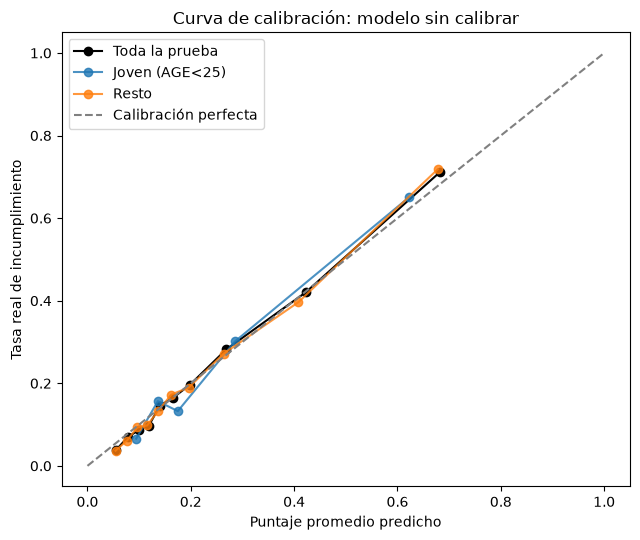

In [19]:
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
import matplotlib.pyplot as plt

def graficar_calibracion(ax, puntajes, titulo):
    frac, media = calibration_curve(y_test, puntajes, n_bins=10, strategy="quantile")
    ax.plot(media, frac, marker="o", label="Toda la prueba", color="black")
    for valor_grupo, nombre, n_bins in [(1, "Joven (AGE<25)", 5), (0, "Resto", 10)]:
        mascara = (g_test.values == valor_grupo)     # el grupo chico lleva menos bins
        frac, media = calibration_curve(y_test.values[mascara], puntajes[mascara], n_bins=n_bins, strategy="quantile")
        ax.plot(media, frac, marker="o", label=nombre, alpha=0.8)
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Calibración perfecta")
    ax.set_xlabel("Puntaje promedio predicho")
    ax.set_ylabel("Tasa real de incumplimiento")
    ax.set_title(titulo)
    ax.legend()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
graficar_calibracion(ax, proba_test, "Curva de calibración: modelo sin calibrar")
fig.tight_layout()
fig.savefig(RESULTADOS / "calibracion_sin_calibrar.png", dpi=150)
plt.show()

In [20]:
def puntaje_contra_tasa(puntajes):
    filas = []
    for valor_grupo, nombre in [(1, "Joven"), (0, "Resto")]:
        mascara = (g_test.values == valor_grupo)
        filas.append({"grupo": nombre, "puntaje_promedio": puntajes[mascara].mean(),
                      "tasa_real": y_test.values[mascara].mean()})
    return pd.DataFrame(filas)

print(puntaje_contra_tasa(proba_test).round(4).to_string(index=False))

grupo  puntaje_promedio  tasa_real
Joven            0.2625     0.2611
Resto            0.2188     0.2172


La curva está pegada a la diagonal en toda la prueba y en el resto. En jóvenes oscila más porque cada punto
resume solo unos 166 clientes. El puntaje promedio coincide con la tasa real: 0.2625 contra 0.2611 en jóvenes y 0.2188 contra
0.2172 en el resto. Es lo que predice el inciso (c) de la teoría: $E[S \mid G=g] = p_g$ si el puntaje está calibrado.

### Calibración para comparar

     version   Brier    AUC
sin calibrar 0.13271 0.7887
   isotónica 0.13229 0.7900

grupo  puntaje_promedio  tasa_real
Joven            0.2689     0.2611
Resto            0.2183     0.2172

Brier sin calibrar - Brier isotónica: 0.00042, IC 95%: [-0.00006, 0.00092]


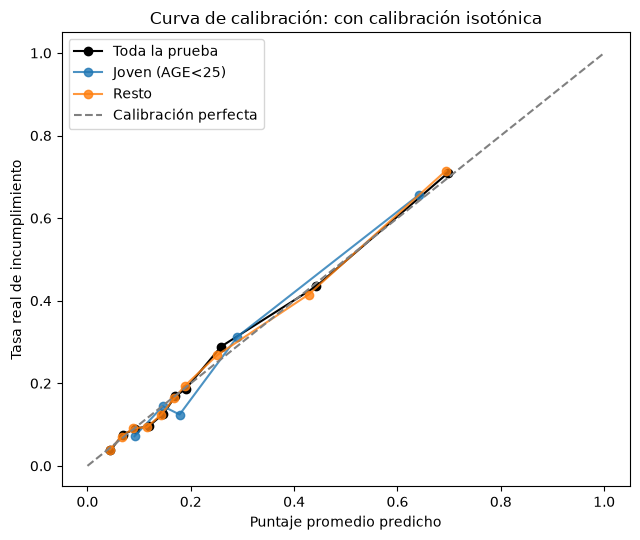

In [21]:
from sklearn.base import clone

modelo_calibrado = CalibratedClassifierCV(clone(mejor_modelo.best_estimator_), method="isotonic", cv=cv)
modelo_calibrado.fit(X_train, y_train)
proba_test_cal = modelo_calibrado.predict_proba(X_test)[:, 1]

comparacion_cal = pd.DataFrame([
    {"version": "sin calibrar", "Brier": brier_score_loss(y_test, proba_test), "AUC": roc_auc_score(y_test, proba_test)},
    {"version": "isotónica", "Brier": brier_score_loss(y_test, proba_test_cal), "AUC": roc_auc_score(y_test, proba_test_cal)},
])
comparacion_cal.to_csv(RESULTADOS / "comparacion_calibracion.csv", index=False)
print(comparacion_cal.round(5).to_string(index=False))
print()
print(puntaje_contra_tasa(proba_test_cal).round(4).to_string(index=False))

# ¿La mejora en Brier se distingue del ruido? Bootstrap pareado sobre la prueba.
rng = np.random.default_rng(SEMILLA)
mejora = np.empty(N_REPLICAS)
y_arr = y_test.values
for i in range(N_REPLICAS):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    mejora[i] = brier_score_loss(y_arr[idx], proba_test[idx]) - brier_score_loss(y_arr[idx], proba_test_cal[idx])
print(f"\nBrier sin calibrar - Brier isotónica: {mejora.mean():.5f}, "
      f"IC 95%: [{np.percentile(mejora, 2.5):.5f}, {np.percentile(mejora, 97.5):.5f}]")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
graficar_calibracion(ax, proba_test_cal, "Curva de calibración: con calibración isotónica")
fig.tight_layout()
fig.savefig(RESULTADOS / "calibracion_isotonica.png", dpi=150)
plt.show()

La calibración isotónica casi no cambia nada. El Brier pasa de 0.13271 a 0.13229 y el AUC de 0.7887 a 0.7900. El intervalo de la mejora en Brier, [-0.00006, 0.00092], incluye el 0 (por muy poco, y la mejora media es de solo 0.0004). En jóvenes el promedio se aleja de la tasa real: 0.2689 contra 0.2611 (sin calibrar era 0.2625); en el resto queda en 0.2183 contra 0.2172.

Me quedo con el modelo sin calibrar. Ya está calibrado hasta donde esta prueba permite medir, y la isotónica no da una mejora que se distinga claramente del ruido.

In [25]:
CALIBRAR = False

modelo_final = modelo_calibrado if CALIBRAR else mejor_modelo.best_estimator_
puntaje_test = proba_test_cal if CALIBRAR else proba_test

## Inciso (c).

In [26]:
def tabla_umbral(y_true, proba, nombre_grupo, umbral=UMBRAL):
    rechazo = (proba >= umbral).astype(int)        # 1 = se rechaza el crédito
    return {
        "grupo": nombre_grupo, "umbral": umbral, "n": len(y_true), "p": y_true.mean(),
        "tasa_rechazo": rechazo.mean(),
        "PPV": y_true[rechazo == 1].mean() if rechazo.sum() > 0 else np.nan,   # rechazados que no iban a pagar
        "FPR": rechazo[y_true == 0].mean(),                                     # pagaban y se les rechazó
        "FNR": 1 - rechazo[y_true == 1].mean(),                                 # no pagaban y se les aceptó
    }

def tabla_por_grupo(puntajes, umbral_joven=UMBRAL, umbral_resto=UMBRAL):
    filas = []
    for valor_grupo, nombre, umbral in [(1, "Joven", umbral_joven), (0, "Resto", umbral_resto)]:
        mascara = (g_test.values == valor_grupo)
        filas.append(tabla_umbral(y_test.values[mascara], puntajes[mascara], nombre, umbral))
    return pd.DataFrame(filas)

tabla = tabla_por_grupo(puntaje_test)
tabla.to_csv(RESULTADOS / "tabla_umbral_unico.csv", index=False)
print(tabla.round(4).to_string(index=False))

grupo  umbral    n      p  tasa_rechazo    PPV    FPR    FNR
Joven    0.25  831 0.2611        0.3177 0.5455 0.1954 0.3364
Resto    0.25 8169 0.2172        0.2610 0.4934 0.1689 0.4070


In [27]:
for _, fila in tabla.iterrows():
    fpr_identidad = (fila["p"] / (1 - fila["p"])) * ((1 - fila["PPV"]) / fila["PPV"]) * (1 - fila["FNR"])
    print(f"{fila['grupo']}: FPR real = {fila['FPR']:.6f}, FPR por identidad = {fpr_identidad:.6f}")

Joven: FPR real = 0.195440, FPR por identidad = 0.195440
Resto: FPR real = 0.168882, FPR por identidad = 0.168882


Con el mismo umbral de 0.25, los jóvenes tienen más rechazos (31.8 % contra 26.1 %) y más FPR (19.5 % contra 16.9 %).
También tienen menos FNR (33.6 % contra 40.7 %): se les escapan menos incumplidos. Su PPV es mayor (0.55 contra 0.49).

### Bootstrap de las diferencias entre grupos

Se remuestrea cada grupo por separado, así cada réplica conserva los 2 tamaños de grupo y el grupo chico no
varía por azar. El modelo queda fijo: el intervalo mide la incertidumbre por la muestra de prueba, no la del entrenamiento.

In [28]:
def rechazo_por_grupo(puntajes, grupos, umbral_joven, umbral_resto):
    umbrales = np.where(grupos == 1, umbral_joven, umbral_resto)
    return (puntajes >= umbrales).astype(int)

def diferencias(y_true, grupos, rechazo):
    def tasas(m):
        y_m, r_m = y_true[m], rechazo[m]
        return (r_m[y_m == 0].mean(), 1 - r_m[y_m == 1].mean(), y_m[r_m == 1].mean(), r_m.mean())
    fpr_j, fnr_j, ppv_j, rech_j = tasas(grupos == 1)
    fpr_r, fnr_r, ppv_r, rech_r = tasas(grupos == 0)
    return {"ΔFPR": fpr_j - fpr_r, "ΔFNR": fnr_j - fnr_r, "ΔPPV": ppv_j - ppv_r, "Δrechazo": rech_j - rech_r}

y_arr = y_test.values
g_arr = g_test.values
idx_joven = np.flatnonzero(g_arr == 1)
idx_resto = np.flatnonzero(g_arr == 0)

def remuestreos():
    rng = np.random.default_rng(SEMILLA)     # misma semilla: todas las comparaciones usan las mismas réplicas
    for _ in range(N_REPLICAS):
        yield np.concatenate([rng.choice(idx_joven, len(idx_joven)), rng.choice(idx_resto, len(idx_resto))])

def ic_diferencias(puntajes, umbral_joven=UMBRAL, umbral_resto=UMBRAL):
    rechazo = rechazo_por_grupo(puntajes, g_arr, umbral_joven, umbral_resto)
    puntual = diferencias(y_arr, g_arr, rechazo)
    replicas = pd.DataFrame([diferencias(y_arr[i], g_arr[i], rechazo[i]) for i in remuestreos()])
    salida = pd.DataFrame({
        "Joven - Resto": puntual,
        "IC95_inf": replicas.quantile(0.025),
        "IC95_sup": replicas.quantile(0.975),
    })
    salida["incluye_0"] = (salida["IC95_inf"] <= 0) & (salida["IC95_sup"] >= 0)
    return salida

ic_base = ic_diferencias(puntaje_test)
ic_base.to_csv(RESULTADOS / "ic_umbral_unico.csv")
print(ic_base.round(4).to_string())

          Joven - Resto  IC95_inf  IC95_sup  incluye_0
ΔFPR             0.0266   -0.0062    0.0591       True
ΔFNR            -0.0706   -0.1354   -0.0084      False
ΔPPV             0.0520   -0.0101    0.1193       True
Δrechazo         0.0567    0.0227    0.0880      False


Las diferencias se leen en puntos porcentuales, jóvenes menos resto.

- **ΔFPR:** +2.7, IC [-0.6, 5.9]. Incluye el 0, así que con la prueba no puedo descartar que sea ruido.
- **ΔPPV:** +5.2, IC [-1.0, 11.9]. También incluye el 0.
- **ΔFNR:** -7.1, IC [-13.5, -0.8]. No incluye el 0: probablemente es una diferencia real.
- **Δrechazo:** +5.7, IC [2.3, 8.8]. No incluye el 0: probablemente es una diferencia real.

La métrica que elegí, la FPR, es justamente una de las que no queda demostrada. Los puntajes fuera de pliegue del entrenamiento, con 1,854 jóvenes,
apuntan en la misma dirección (+5.8 puntos), pero eso no es una prueba independiente. Además son cuatro intervalos a la vez, así que uno que
apenas excluye el 0, como el de FNR, hay que leerlo con cuidado.

## Inciso (d).
Los umbrales se eligen con puntajes fuera de pliegue del entrenamiento y después se aplican una sola vez a la prueba.
Definición elegida en la teoría: igualar la FPR. Se acepta una diferencia de hasta 1 punto porcentual porque la malla
de umbrales es discreta.

In [31]:
from sklearn.model_selection import cross_val_predict

proba_train_oof = cross_val_predict(clone(modelo_final), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

def ganancia(y_true, rechazo):
    acepta = (rechazo == 0)
    pagan = (y_true == 0)
    return G * (acepta & pagan).sum() - L * (acepta & ~pagan).sum()

y_tr, g_tr = y_train.values, g_train.values
malla = np.round(np.arange(0.05, 0.61, 0.01), 2)

# Métricas por grupo para cada umbral; cada par solo las combina
por_umbral = {}
for valor_grupo in (1, 0):
    y_g, s_g = y_tr[g_tr == valor_grupo], proba_train_oof[g_tr == valor_grupo]
    por_umbral[valor_grupo] = {}
    for u in malla:
        r = (s_g >= u).astype(int)
        por_umbral[valor_grupo][u] = (r[y_g == 0].mean(), 1 - r[y_g == 1].mean(), ganancia(y_g, r))

filas_malla = []
for u_joven in malla:
    for u_resto in malla:
        fpr_j, fnr_j, gan_j = por_umbral[1][u_joven]
        fpr_r, fnr_r, gan_r = por_umbral[0][u_resto]
        filas_malla.append({"u_joven": u_joven, "u_resto": u_resto, "delta_fpr": fpr_j - fpr_r,
                            "delta_fnr": fnr_j - fnr_r, "ganancia": gan_j + gan_r})
resultados = pd.DataFrame(filas_malla)

In [32]:
TOLERANCIA = 0.01

candidatos = resultados[resultados["delta_fpr"].abs() <= TOLERANCIA]
mejor_par = candidatos.loc[candidatos["ganancia"].idxmax()]
u_joven_elegido, u_resto_elegido = float(mejor_par["u_joven"]), float(mejor_par["u_resto"])

base = resultados[(resultados["u_joven"] == UMBRAL) & (resultados["u_resto"] == UMBRAL)].iloc[0]

# Alternativa: dejar al grupo grande en el umbral óptimo y mover solo a los jóvenes
solo_joven = candidatos[candidatos["u_resto"] == UMBRAL]
solo_joven = solo_joven.loc[solo_joven["ganancia"].idxmax()] if len(solo_joven) else None

print("Par elegido en entrenamiento (fuera de pliegue):")
print(mejor_par.round(4).to_string())
print("\nPunto base (0.25, 0.25):")
print(base.round(4).to_string())
print("\nAlternativa con u_resto = 0.25:")
print(solo_joven.round(4).to_string() if solo_joven is not None else "No hay par dentro de la tolerancia")

Par elegido en entrenamiento (fuera de pliegue):
u_joven         0.3200
u_resto         0.2600
delta_fpr       0.0037
delta_fnr      -0.0022
ganancia     7915.0000

Punto base (0.25, 0.25):
u_joven         0.2500
u_resto         0.2500
delta_fpr       0.0581
delta_fnr      -0.0637
ganancia     7820.0000

Alternativa con u_resto = 0.25:
u_joven         0.3200
u_resto         0.2500
delta_fpr      -0.0076
delta_fnr       0.0026
ganancia     7806.0000


In [33]:
# Aplica el par elegido a la PRUEBA
tabla_intervencion = tabla_por_grupo(puntaje_test, u_joven_elegido, u_resto_elegido)
tabla_intervencion.to_csv(RESULTADOS / "tabla_intervencion.csv", index=False)
print(tabla_intervencion.round(4).to_string(index=False))

rechazo_base = rechazo_por_grupo(puntaje_test, g_arr, UMBRAL, UMBRAL)
rechazo_int = rechazo_por_grupo(puntaje_test, g_arr, u_joven_elegido, u_resto_elegido)
ganancia_base = ganancia(y_arr, rechazo_base)
ganancia_int = ganancia(y_arr, rechazo_int)
costo = ganancia_base - ganancia_int

# Bootstrap pareado: la misma réplica se evalúa con las dos reglas
costos = np.array([ganancia(y_arr[i], rechazo_base[i]) - ganancia(y_arr[i], rechazo_int[i]) for i in remuestreos()])
ic_costo = np.percentile(costos, [2.5, 97.5])

print(f"\nGanancia base (umbral único {UMBRAL}): {ganancia_base}")
print(f"Ganancia con intervención: {ganancia_int}")
print(f"Costo: {costo} ({costo / ganancia_base * 100:.2f}%), IC 95%: [{ic_costo[0]:.0f}, {ic_costo[1]:.0f}]")
pd.DataFrame([{"ganancia_base": ganancia_base, "ganancia_intervencion": ganancia_int, "costo": costo,
               "costo_pct": costo / ganancia_base * 100, "IC95_inf": ic_costo[0], "IC95_sup": ic_costo[1]}]
            ).to_csv(RESULTADOS / "costo_intervencion.csv", index=False)

grupo  umbral    n      p  tasa_rechazo    PPV    FPR    FNR
Joven    0.32  831 0.2611        0.2611 0.5806 0.1482 0.4194
Resto    0.26 8169 0.2172        0.2481 0.5081 0.1559 0.4194

Ganancia base (umbral único 0.25): 3424
Ganancia con intervención: 3416
Costo: 8 (0.23%), IC 95%: [-35, 51]


En entrenamiento, el mejor par con |ΔFPR| ≤ 0.01 es (0.32, 0.26), con ganancia de 7,915 contra 7,820 del umbral único (0.25, 0.25).
La alternativa de mover solo a los jóvenes, (0.32, 0.25), gana menos: 7,806.

En prueba, la FPR queda en 14.8 % para jóvenes y 15.6 % para el resto. La ganancia baja de 3,424 a 3,416, un costo de 8 unidades (0.23 %).
Su IC del 95 %, [-35, 51], incluye el 0: el costo puede ir de una pequeña ganancia a una pérdida de cerca de 1.5 % de la ganancia. Por lo tanto, en esta prueba no se distingue de cero.

Que en entrenamiento el par elegido gane más que el umbral único no contradice la teoría. El umbral 0.25 es óptimo si el puntaje es la probabilidad verdadera; con puntajes fuera de pliegue y datos finitos, la ganancia empírica tiene ruido. En prueba la relación se invierte (costo de 8), lo que es consistente con ese ruido.

### ¿A quién le cambió la decisión?

In [34]:
filas_cambio = []
for valor_grupo, nombre in [(1, "Joven"), (0, "Resto")]:
    m = (g_arr == valor_grupo)
    for sentido, seleccion in [("rechazado → aceptado", (rechazo_base == 1) & (rechazo_int == 0)),
                               ("aceptado → rechazado", (rechazo_base == 0) & (rechazo_int == 1))]:
        cambiaron = m & seleccion
        filas_cambio.append({"grupo": nombre, "cambio": sentido, "clientes": int(cambiaron.sum()),
                             "tasa_incumplimiento": y_arr[cambiaron].mean() if cambiaron.any() else np.nan,
                             "ganancia_del_cambio": ganancia(y_arr[cambiaron], np.zeros(cambiaron.sum(), dtype=int))})
cambios = pd.DataFrame(filas_cambio)
cambios.to_csv(RESULTADOS / "clientes_que_cambian.csv", index=False)
print(cambios.round(4).to_string(index=False))

grupo               cambio  clientes  tasa_incumplimiento  ganancia_del_cambio
Joven rechazado → aceptado        47               0.3830                  -25
Joven aceptado → rechazado         0                  NaN                    0
Resto rechazado → aceptado       105               0.2095                   17
Resto aceptado → rechazado         0                  NaN                    0


Como los dos umbrales suben, nadie resulta rechazado por la intervención. Solo hay 152 clientes que pasan de rechazados a aceptados:
47 jóvenes y 105 del resto.

No todos son rentables. De esos jóvenes no pagó el 38.3 %, por encima de 0.25, el punto en el que aceptar deja de convenir, así que aceptarlos pierde 25 unidades.
Del resto no pagó el 21.0 %, por debajo de 0.25, así que aceptarlos gana 17. El neto es -25 + 17 = -8, que es exactamente el costo calculado arriba.
Que el grupo del resto resulte rentable puede ser ruido (son solo 105 clientes) o indicar que entre 0.25 y 0.26 el modelo sobrestima un poco el riesgo.
Los jóvenes que aceptamos y no pagaron también salen perjudicados: recibieron un crédito que no pudieron pagar.

### Ganancia contra diferencia de FPR

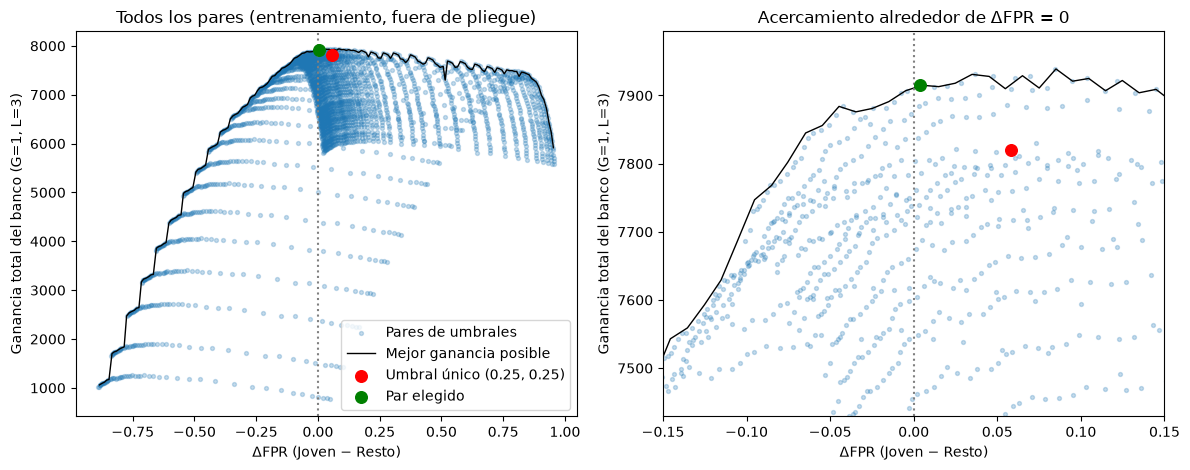

In [36]:
intervalos = pd.cut(resultados["delta_fpr"], bins=np.arange(-1.0, 1.01, 0.01))
frontera = resultados.groupby(intervalos, observed=True).agg(delta_fpr=("delta_fpr", "mean"), ganancia=("ganancia", "max"))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax in ejes:
    ax.scatter(resultados["delta_fpr"], resultados["ganancia"], alpha=0.25, s=8, label="Pares de umbrales")
    ax.plot(frontera["delta_fpr"], frontera["ganancia"], color="black", linewidth=1, label="Mejor ganancia posible")
    ax.scatter(base["delta_fpr"], base["ganancia"], color="red", s=70, label="Umbral único (0.25, 0.25)", zorder=5)
    ax.scatter(mejor_par["delta_fpr"], mejor_par["ganancia"], color="green", s=70, label="Par elegido", zorder=5)
    ax.axvline(0, color="gray", linestyle=":")
    ax.set_xlabel("ΔFPR (Joven − Resto)")
    ax.set_ylabel("Ganancia total del banco (G=1, L=3)")
ejes[0].set_title("Todos los pares (entrenamiento, fuera de pliegue)")
ejes[0].legend(loc="lower right")
ejes[1].set_title("Acercamiento alrededor de ΔFPR = 0")
ejes[1].set_xlim(-0.15, 0.15)
ejes[1].set_ylim(base["ganancia"] * 0.95, max(base["ganancia"], mejor_par["ganancia"]) * 1.01)
fig.tight_layout()
fig.savefig(RESULTADOS / "ganancia_vs_delta_fpr.png", dpi=150)
plt.show()

Cada punto es un par de umbrales y la línea negra es la mejor ganancia posible para cada ΔFPR. A la izquierda se ve que los pares extremos destruyen la
ganancia. A la derecha, cerca de ΔFPR = 0, la frontera es casi plana.

En entrenamiento el par elegido (verde) tiene ganancia 7,915 y el umbral único (rojo) 7,820. Que un par distinto supere al (0.25, 0.25) aunque la teoría diga que ese umbral es el óptimo
indica que el ruido de esta curva es del orden de decenas de unidades, y es otra razón para no sobreinterpretar el costo calculado en prueba (8 unidades).

### ¿Qué pasó con las otras definiciones?

In [37]:
ic_int = ic_diferencias(puntaje_test, u_joven_elegido, u_resto_elegido)
ic_int.to_csv(RESULTADOS / "ic_intervencion.csv")

print("Con umbral único:")
print(ic_base.round(4).to_string())
print("\nCon intervención:")
print(ic_int.round(4).to_string())

Con umbral único:
          Joven - Resto  IC95_inf  IC95_sup  incluye_0
ΔFPR             0.0266   -0.0062    0.0591       True
ΔFNR            -0.0706   -0.1354   -0.0084      False
ΔPPV             0.0520   -0.0101    0.1193       True
Δrechazo         0.0567    0.0227    0.0880      False

Con intervención:
          Joven - Resto  IC95_inf  IC95_sup  incluye_0
ΔFPR            -0.0077   -0.0368    0.0210       True
ΔFNR            -0.0000   -0.0678    0.0695       True
ΔPPV             0.0725    0.0050    0.1439      False
Δrechazo         0.0130   -0.0177    0.0427       True


Igualar la FPR también acercó otras métricas: ΔFNR pasa de -7.1 a 0.0 puntos y Δrechazo de +5.7 a +1.3, y los dos intervalos ahora incluyen el 0 (ΔFNR [-6.8, 7.0], Δrechazo [-1.8, 4.3]).
ΔFPR queda en -0.8, IC [-3.7, 2.1], que también incluye el 0.

La paridad predictiva empeora: ΔPPV pasa de +5.2 a +7.3 puntos, y su IC [0.5, 14.4] ya no incluye el 0. Es lo que predice el inciso (b): si las tasas de incumplimiento son distintas
y FPR y FNR casi se igualan, la PPV no puede ser igual.

El puntaje sigue calibrado por grupo porque no lo modifiqué, pero la decisión ya no lo trata igual: con puntaje 0.30, un joven se acepta (umbral 0.32) y un cliente del resto se rechaza (umbral 0.26).
El FNR también sube: de 33.6 % a 41.9 % en jóvenes y de 40.7 % a 41.9 % en el resto. El banco deja pasar a más clientes que no pagarán.

## Inciso (e)

In [38]:
columnas_sin_age = [c for c in columnas if c != "AGE"]
X_train_sin_age = X_train[columnas_sin_age]
X_test_sin_age = X_test[columnas_sin_age]

if mejor_modelo is grid_hgb:
    parametros = {k.replace("clf__", ""): v for k, v in grid_hgb.best_params_.items()}
    modelo_sin_age = crear_hgb(columnas_sin_age, **parametros)
else:
    modelo_sin_age = crear_lr(columnas_sin_age, C=grid_lr.best_params_["clf__C"])

modelo_sin_age.fit(X_train_sin_age, y_train)
proba_test_sin_age = modelo_sin_age.predict_proba(X_test_sin_age)[:, 1]

tabla_sin_age = tabla_por_grupo(proba_test_sin_age)
tabla_sin_age.to_csv(RESULTADOS / "tabla_sin_age.csv", index=False)
ic_sin_age = ic_diferencias(proba_test_sin_age)
ic_sin_age.to_csv(RESULTADOS / "ic_sin_age.csv")

print("Con AGE:")
print(tabla.round(4).to_string(index=False))
print("\nSin AGE:")
print(tabla_sin_age.round(4).to_string(index=False))
print("\nDiferencias sin AGE:")
print(ic_sin_age.round(4).to_string())
print(f"\nAUC sin AGE: {roc_auc_score(y_test, proba_test_sin_age):.4f} (con AGE: {roc_auc_score(y_test, puntaje_test):.4f})")
print("\nCalibración por grupo sin AGE:")
print(puntaje_contra_tasa(proba_test_sin_age).round(4).to_string(index=False))

Con AGE:
grupo  umbral    n      p  tasa_rechazo    PPV    FPR    FNR
Joven    0.25  831 0.2611        0.3177 0.5455 0.1954 0.3364
Resto    0.25 8169 0.2172        0.2610 0.4934 0.1689 0.4070

Sin AGE:
grupo  umbral    n      p  tasa_rechazo    PPV    FPR    FNR
Joven    0.25  831 0.2611        0.3225 0.5522 0.1954 0.3180
Resto    0.25 8169 0.2172        0.2621 0.4900 0.1708 0.4087

Diferencias sin AGE:
          Joven - Resto  IC95_inf  IC95_sup  incluye_0
ΔFPR             0.0247   -0.0075    0.0564       True
ΔFNR            -0.0907   -0.1544   -0.0241      False
ΔPPV             0.0623    0.0010    0.1294      False
Δrechazo         0.0604    0.0265    0.0911      False

AUC sin AGE: 0.7880 (con AGE: 0.7887)

Calibración por grupo sin AGE:
grupo  puntaje_promedio  tasa_real
Joven            0.2638     0.2611
Resto            0.2186     0.2172


Las diferencias no desaparecen. Sin `AGE`, ΔFPR es +2.5 puntos, IC [-0.8, 5.6] (con `AGE` era +2.7); ΔFNR es -9.1, IC [-15.4, -2.4]; ΔPPV es +6.2, IC [0.1, 12.9]; y Δrechazo es +6.0, IC [2.7, 9.1].
Los intervalos con y sin `AGE` se solapan casi por completo, así que no puedo afirmar que quitarla cambie la equidad en ningún sentido. Lo que sí muestra es que no la arregla.

El AUC casi no cambia (0.7880 contra 0.7887), y la calibración por grupo tampoco (0.2638 contra 0.2611 en jóvenes sin `AGE`; con `AGE` era 0.2625). Hay dos razones: las tasas de incumplimiento siguen siendo distintas,
26.1 % contra 21.7 %, y por eso el inciso (b) aplica con o sin `AGE`; además, otras variables contienen la información de la edad, como muestra la siguiente celda.

### ¿Qué variables se relacionan con la edad?

In [39]:
# ¿Se puede adivinar el grupo sin usar AGE? Se mide con validación cruzada en entrenamiento.
modelo_predice_joven = crear_hgb(columnas_sin_age)
auc_predecir_joven = cross_val_score(modelo_predice_joven, X_train_sin_age, g_train, scoring="roc_auc", cv=cv, n_jobs=-1)
print(f"AUC prediciendo 'joven' sin usar AGE: {auc_predecir_joven.mean():.4f}")

# Qué tan bien separa cada variable, por sí sola, a los dos grupos (0.5 = nada)
separacion = pd.Series({
    c: max(roc_auc_score(g_train, X_train[c]), 1 - roc_auc_score(g_train, X_train[c])) for c in columnas_sin_age
}).sort_values(ascending=False).rename("AUC_individual")
separacion.to_csv(RESULTADOS / "variables_relacionadas_edad.csv")
print("\n", separacion.head(8).round(3).to_string())

print("\nMediana de LIMIT_BAL:", X_train.groupby(g_train)["LIMIT_BAL"].median().to_dict())
for c in ["MARRIAGE", "EDUCATION"]:
    print(f"\nDistribución de {c} por grupo (1 = joven):")
    print(pd.crosstab(X_train[c], g_train, normalize="columns").round(3).to_string())

AUC prediciendo 'joven' sin usar AGE: 0.8769

 LIMIT_BAL    0.812
MARRIAGE     0.685
PAY_AMT6     0.605
PAY_AMT2     0.597
PAY_2        0.594
PAY_AMT5     0.593
PAY_3        0.591
PAY_AMT4     0.591

Mediana de LIMIT_BAL: {0: 150000.0, 1: 50000.0}

Distribución de MARRIAGE por grupo (1 = joven):
joven         0      1
MARRIAGE              
1         0.487  0.108
2         0.499  0.888
3         0.013  0.004

Distribución de EDUCATION por grupo (1 = joven):
joven          0      1
EDUCATION              
1          0.362  0.265
2          0.454  0.607
3          0.168  0.114
4          0.017  0.013


Sin usar AGE, se puede distinguir a un joven de otro cliente con AUC de 0.877. La variable más relacionada es LIMIT_BAL (AUC individual de 0.812, con mediana de 50,000 contra 150,000). Le sigue MARRIAGE (0.685): 88.8 % de los jóvenes son solteros contra 49.9 % del resto. EDUCATION también cambia: 60.7 % de los jóvenes tiene universidad contra 45.4 % del resto.

Las variables de pagos aportan poco una por una (alrededor de 0.6). Quitar AGE no quita la información de la edad, porque el modelo puede recuperarla de estas variables.